# Calculus, plotting and Sage basics

Each section below was a separate notebook. The sections share one kernel, so run a section from its own first cell.

## Sage basics: plots, calculus and matrices

In [1]:
f(x) = x^3 - x
fp(x) = f(x).derivative()

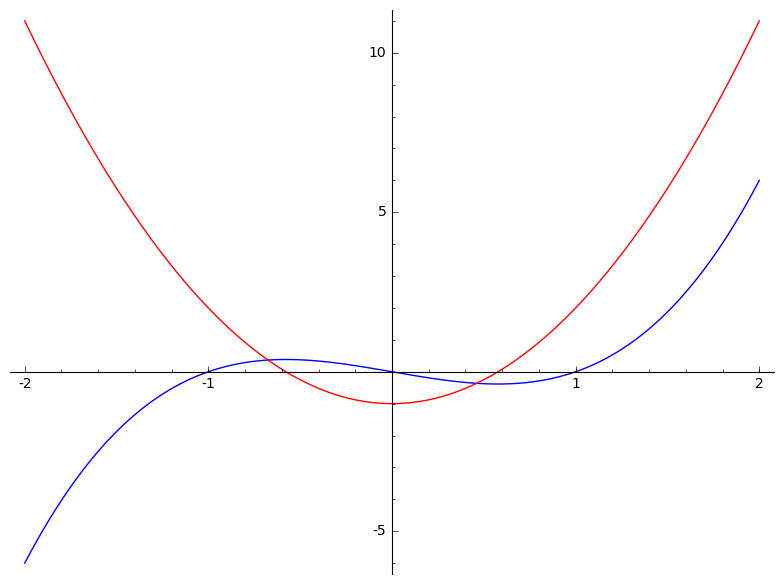

In [2]:
plot(f, -2, 2, color='blue') + plot(fp, -2, 2, color='red')

In [3]:
n(pi)

3.14159265358979

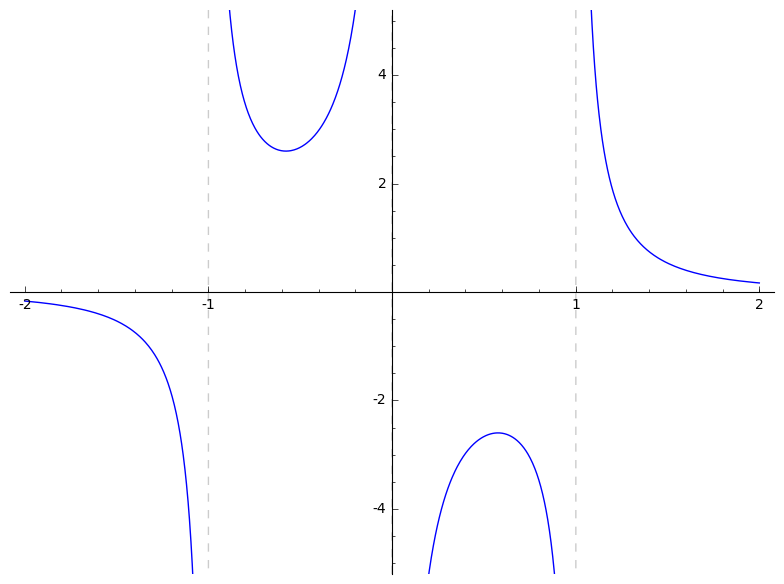

In [4]:
plot(1/(x^3 - x), -2, 2, ymin = -5, ymax = 5, detect_poles='show')

In [5]:
M = Matrix(2,3, [1,2,3,4,5,6])
M

[1 2 3]
[4 5 6]

In [6]:
M.rref()

[ 1  0 -1]
[ 0  1  2]

In [7]:
# Explicit function plots
var('x y')
p = plot3d(x^2 + y^2, (x,-2,2), (y,-2,2))
show(p, viewer='threejs')

Graphics3d Object

In [8]:
# Parametric Plots
var('t')
show(parametric_plot3d( [cos(t), sin(t), t], (t,0,4*pi) ), viewer='threejs')

Graphics3d Object

In [9]:
# Implicit plot - plots where f = 0
f(x,y,z) = 4*x^2*(x^2 + y^2 + z^2 + z) + y^2*(y^2 + z^2 - 1)
show(f)
show(implicit_plot3d(f, (x,-1/2,1/2), (y,-1,1), (z,-1,1)), viewer='threejs')

(x, y, z) |--> 4*(x^2 + y^2 + z^2 + z)*x^2 + (y^2 + z^2 - 1)*y^2

Graphics3d Object

In [10]:
show(solve(x^2/2 -x-2, x))

[x == -sqrt(5) + 1, x == sqrt(5) + 1]

In [11]:
show(solve(x^4 - 2, x))

[x == I*2^(1/4), x == -2^(1/4), x == -I*2^(1/4), x == 2^(1/4)]

In [12]:
f(x,y) = x*y + sin(x^2) + e^-y
show(f.gradient())

(x, y) |--> (2*x*cos(x^2) + y, x - e^(-y))

In [13]:
show(integral(x*sin(x^2), x))

-1/2*cos(x^2)

In [14]:
show(integral(x*sin(x^2), x, 0, 2*pi))

-1/2*cos(4*pi^2) + 1/2

In [15]:
f(x) = (x^3-x)/(x^2+5*x+6)
show(f)
show(f.partial_fraction())

x |--> (x^3 - x)/(x^2 + 5*x + 6)

x |--> x + 24/(x + 3) - 6/(x + 2) - 5

In [16]:
show(integral(1/x^2, x, 2, oo))

1/2

In [17]:
factor(2008)

2^3 * 251

In [18]:
gcd(120,64)

8

In [19]:
lcm(5,2)

10

In [20]:
gcd([10,25,30])

5

In [21]:
lcm([1,2,3,4,5])

60

In [22]:
euler_phi(12)

4

In [23]:
show(factor(12))
euler_phi(12) == 2 * euler_phi(2) + euler_phi(3)

2^2 * 3

True

In [24]:
divisors(12)

[1, 2, 3, 4, 6, 12]

In [25]:
inverse_mod(3, 7)

5

In [26]:
factorial(5)

120

In [27]:
binomial(4,2)

6

In [28]:
A = Set(['a', 'b', 'c'])
B = Set(['b', 'c', 'd'])
show(A|B)
show(A&B)
show(A-B)

{'a', 'c', 'b', 'd'}

{'c', 'b'}

{'a'}

In [29]:
show(Permutations(A).list())

[['a', 'c', 'b'],
 ['a', 'b', 'c'],
 ['c', 'a', 'b'],
 ['c', 'b', 'a'],
 ['b', 'a', 'c'],
 ['b', 'c', 'a']]

In [30]:
G = Permutations(3)
for i in range(G.cardinality()):
    print(G[i])

[1, 2, 3]
[1, 3, 2]
[2, 1, 3]
[2, 3, 1]
[3, 1, 2]
[3, 2, 1]


In [31]:
A = SetPartitions(4, 3)
for i in range(A.cardinality()):
    print(A[i])

{{1}, {2}, {3, 4}}
{{1}, {2, 4}, {3}}
{{1}, {2, 3}, {4}}
{{1, 4}, {2}, {3}}
{{1, 3}, {2}, {4}}
{{1, 2}, {3}, {4}}


In [32]:
P = Partitions(5)
P.list()

[[5], [4, 1], [3, 2], [3, 1, 1], [2, 2, 1], [2, 1, 1, 1], [1, 1, 1, 1, 1]]

In [33]:
f(x) = (x-2)/(x-3)
limit(f, x=3)

x |--> Infinity

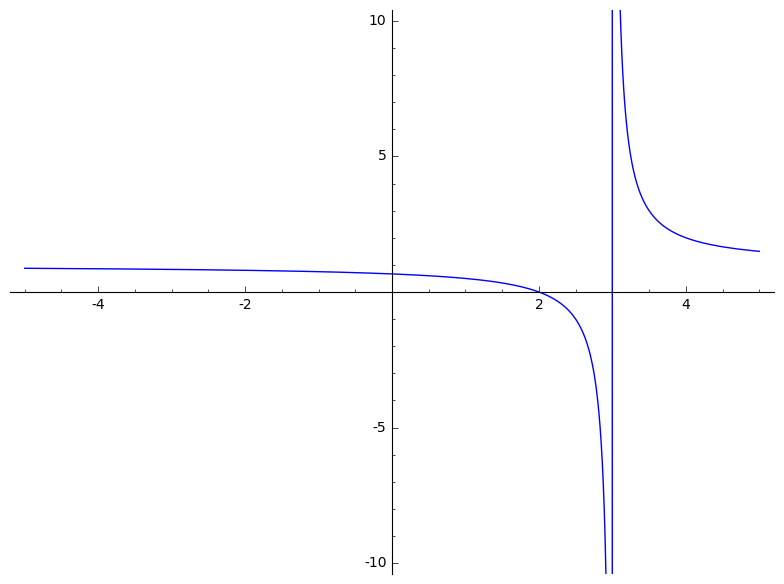

In [34]:
plot(f, (x,-5, 5), ymin=-10, ymax=10)

In [35]:
f(x) = sin(x)
show(taylor(f, x, 0, 5))

x |--> 1/120*x^5 - 1/6*x^3 + x

In [36]:
var('a,b,c')
eqn = [a+b-4*c==1, b-a-3*c==0, a+b==5, 4*a+b-5*c==7]
s = solve(eqn, a,b,c)
s

[]

In [37]:
var('x','y','z')
p = implicit_plot3d(2*x+y+3*z==3, (x,-3,3), (y,-3,3), (z,-3,3), color="lightblue", opacity=0.8)
from sage.plot.plot3d.plot3d import axes
ax = axes(scale=4, radius=1, color='black')
show(p+ax, viewer='threejs')

Graphics3d Object

## Sage examples

### Compute/Plot Taylor Expansions

In [1]:
var('x')
x0  = 0
f   = sin(x)*e^(-x)
p   = plot(f,-1,5, thickness=2)
dot = point((x0,f(x=x0)),pointsize=80,rgbcolor=(1,0,0))

@interact
def _(order=[1..12]):
    ft = f.taylor(x,x0,order)
    pt = plot(ft,-1, 5, color='green', thickness=2)
    pretty_print(html('$f(x)\;=\;%s$'%latex(f)))
    pretty_print(html('$\hat{f}(x;%s)\;=\;%s+\mathcal{O}(x^{%s})$'%(x0,latex(ft),order+1)))
    show(dot + p + pt, ymin = -.5, ymax = 1)

SW50ZXJhY3RpdmUgZnVuY3Rpb24gPGZ1bmN0aW9uIF8gYXQgMHg3ZjQzNjI5YjAzMjA+IHdpdGggMSB3aWRnZXQKICBvcmRlcjogRHJvcGRvd24oZGVzY3JpcHRpb249dSdvcmRlcicsIG9wdGnigKY=


### 3D Plots

In [2]:
def f(x,y):
    return math.sin(y*y+x*x)/math.sqrt(x*x+y*y+.0001)
P = plot3d(f,(-3,3),(-3,3), adaptive=True, color=rainbow(60, 'rgbtuple'), max_bend=.1, max_depth=15)
P.show()

Graphics3d Object

### Matrices Over Finite Fields

In [14]:
M = MatrixSpace(GF(5),5,7)
A = M([2,-1,-1,0,0,0,0,
       -1,0,2,-1,0,0,0,
       0,0,-1,2,-1,0,0,
       0,0,0,-1,2,-1,0,
       0,0,0,0,-1,2,-1
       ])
print(A.rank())
print(A.kernel())
print(A.nullity())
print(A)
print(A.echelon_form())

5
Vector space of degree 5 and dimension 0 over Finite Field of size 5
Basis matrix:
[]
0
[2 4 4 0 0 0 0]
[4 0 2 4 0 0 0]
[0 0 4 2 4 0 0]
[0 0 0 4 2 4 0]
[0 0 0 0 4 2 4]
[1 0 0 0 0 0 4]
[0 1 0 0 0 4 0]
[0 0 1 0 0 1 3]
[0 0 0 1 0 2 2]
[0 0 0 0 1 3 1]


In [15]:
M2 = MatrixSpace(GF(5), 4, 6)
B = M2([2,-1,-1,0,0,0,
        -1,0,2,-1,0,0,
        0,0,-1,2,0,-1,
        0,0,0,-1,2,-1
])

print(B.rank())
print(B.kernel())
print(B.nullity())
print(B)
print(B.echelon_form())

4
Vector space of degree 4 and dimension 0 over Finite Field of size 5
Basis matrix:
[]
0
[2 4 4 0 0 0]
[4 0 2 4 0 0]
[0 0 4 2 0 4]
[0 0 0 4 2 4]
[1 0 0 0 4 0]
[0 1 0 0 2 2]
[0 0 1 0 1 3]
[0 0 0 1 3 1]


In [ ]:
# Substituting 

In [20]:
var('y')
var('A,h,e,c,t')

f = (A + 3*y + A^2*y)^3

g = A*(A*c*h + A^-1*h) + h + A^-2 * (A*e + A^-1*c*e)

eight = -A^-3

circ = -A^2-A^-2

hopf = -A^4 - A^-4

result = g(A=t^(-1/4), h=hopf, e=eight, c=circ)

show(result.expand())

A^6/sqrt(t) - 2*A^4 + A^2/sqrt(t) + t^(3/4)/A + 1/(A^2*sqrt(t)) - t^(1/4)/A^3 - 2/A^4 + t^(3/4)/A^5 + 1/(A^6*sqrt(t))

## Calculus in Sage: derivatives, integrals and limits

In [25]:
%display latex

In [26]:
x = var('x')
y = var('y')
t = var('t')

In [28]:
f = log(x)*y + e^(x^2)
f

y*log(x) + e^(x^2)

In [29]:
f.derivative(x)

2*x*e^(x^2) + y/x

In [30]:
g = f.integral(x)
g

(x*log(x) - x)*y - 1/2*I*sqrt(pi)*erf(I*x)

In [31]:
limit(g, x=0)

0

In [42]:
from sympy import Curve, line_integrate
C = Curve([e**t + 1, e**t - 1], (t, 0, ln(2)))
line_integrate(x + y, C, [x, y])

3*sqrt(2)

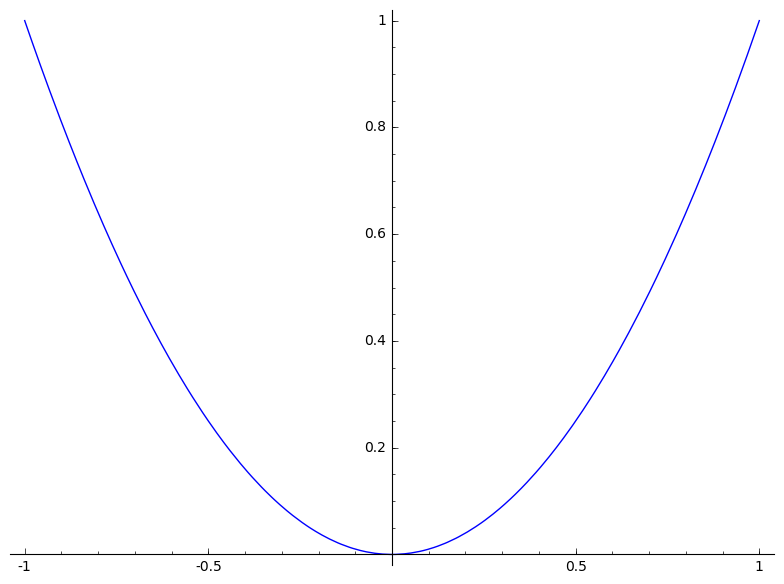

In [51]:
plot(x**2)

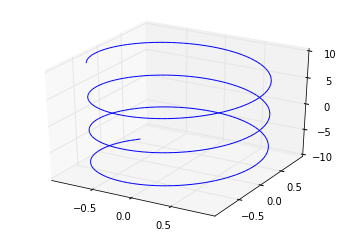

In [56]:
from sympy.plotting import plot3d_parametric_line
t = var('t')
alpha = [cos(t), sin(t), t]
plot3d_parametric_line(*alpha)

In [57]:
s=vector((t,cos(t),0))
ds=diff(s,t)
ds

(1, -sin(t), 0)

In [62]:
f(x, y) = x^2 + x*y + y^2 - 6*x + 2
f.gradient()

(x, y) |--> (2*x + y - 6, x + 2*y)

In [66]:
f(x,y)=x^2*y
f.integrate(x, y/4, 3).integrate(y, 0, 12)

1944/5

In [75]:
m = matrix([[1,1], [1,2]])
m

[1 1]
[1 2]

In [76]:
m.inverse()

[ 2 -1]
[-1  1]

In [81]:
v = vector([1,1])
v

(1, 1)

In [83]:
m * v

(2, 3)

## Simplifying rational expressions

In [16]:
%display latex

f = (17*x-1)^5 * (20* (2*x+6)*(x^2+12)*x + 2*(x^2+12)^2 ) - 425 *(2*x+6) * ((x^2+12)^2 * (17*x-1)^4)
f

-850*(x^2 + 12)^2*(17*x - 1)^4*(x + 3) + 2*(20*(x^2 + 12)*(x + 3)*x + (x^2 + 12)^2)*(17*x - 1)^5

In [7]:
g = 5*(2*x+6)^(4/3) *(17*x+10)^10
g

5*(17*x + 10)^10*(2*x + 6)^(4/3)

In [31]:
h = f/g
h

-2/5*(425*(x^2 + 12)^2*(17*x - 1)^4*(x + 3) - (20*(x^2 + 12)*(x + 3)*x + (x^2 + 12)^2)*(17*x - 1)^5)/((17*x + 10)^10*(2*x + 6)^(4/3))

In [19]:
f2 = 8*(17*x^5 + 69*x^4 + 1443*x^3+ 4656*x^2 + 14868*x + 45936)
f2

136*x^5 + 552*x^4 + 11544*x^3 + 37248*x^2 + 118944*x + 367488

In [22]:
g2 = 5*(2*x+6)^(4/5)*(17*x-1)^6
g2

5*(17*x - 1)^6*(2*x + 6)^(4/5)

In [24]:
h2 = f2/g2
h2

8/5*(17*x^5 + 69*x^4 + 1443*x^3 + 4656*x^2 + 14868*x + 45936)/((17*x - 1)^6*(2*x + 6)^(4/5))

In [27]:
bool(h2 == h)

False

In [28]:
h2(0)

61248/5*6^(1/5)

In [29]:
h(0)

-319/1562500000*6^(2/3)

## Plotting scratch

In [1]:
var('x')

x

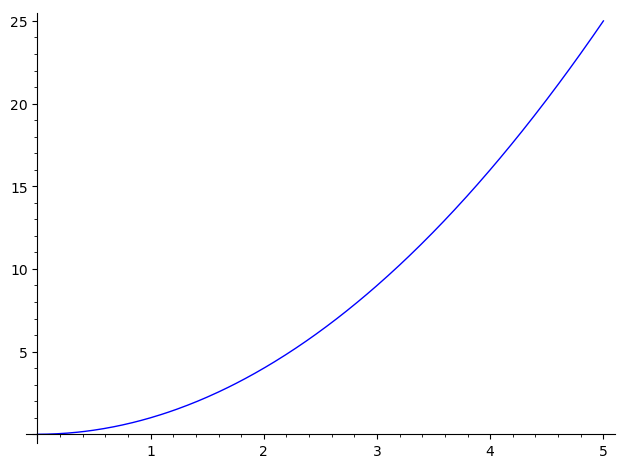

In [8]:
plot(x*x, (x, 0, 5))

In [9]:
f(x) = x*x

In [10]:
f(3)

9

## 3D matplotlib scratch

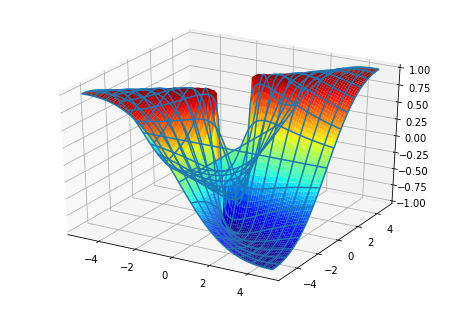

In [4]:

from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
import pylab
import numpy as np
import mpmath
mpmath.dps = 5

# Use instead of arg for a continuous phase
def arg2(x):
    return mpmath.sin(mpmath.arg(x))

#f = lambda z: abs(mpmath.loggamma(z))
#f = lambda z: arg2(mpmath.exp(z))
#f = lambda z: abs(mpmath.besselj(3,z))
f = lambda z: arg2(z^2+2)

fig = pylab.figure()
ax = Axes3D(fig)
X = np.arange(-5, 5, 0.125)
Y = np.arange(-5, 5, 0.125)
X, Y = np.meshgrid(X, Y)
xn, yn = X.shape
W = X*0
for xk in range(xn):
    for yk in range(yn):
        try:
            z = complex(X[xk,yk],Y[xk,yk])
            w = float(f(z))
            if w != w:
                raise ValueError
            W[xk,yk] = w
        except (ValueError, TypeError, ZeroDivisionError):
            # can handle special values here
            pass
    #print(xk, xn)

# can comment out one of these
ax.plot_surface(X, Y, W, rstride=1, cstride=1, cmap=cm.jet)
ax.plot_wireframe(X, Y, W, rstride=5, cstride=5)

pylab.show()